In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import torch
import pandas as pd
import seaborn as sns
from imlff.common.util import proj_path
from imlff.analysis.util import dedup_by_latest_tag, pick_best_by_val_forces


import pandas as pd


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

pd.set_option('display.max_rows', 500)
pd.set_option("display.max_colwidth", None)

# Load summary df

In [ ]:
from imlff.analysis.base import fix_wandb_df

column_tag = 'best_manual_tag'
metric_val = 'best_manual__val_forces_MAE'
metric_test = 'best_manual__test_forces_MAE'

best_files = [
    'result_summary/runs/2026-06-25_ALL_128/runs_best_per_group_test',
]
not_run_ids = []

loaded_df = pd.concat([
    pd.read_csv(proj_path(f'{f}.csv', verbose=False)) for f in best_files
])
loaded_df = fix_wandb_df(loaded_df, verbose=False)

# Analyse summary df

In [9]:
gcols = [
    'AtomisticRepresentationClass',
    'Dataset',
    'molecule',
    'n_z', 
    'type',
    'layer_calls',
    'n_interactions',
    'shared_interactions',
    'n_schnets',
    'shared_schnets',
    'norm_o',
    'norm_s',
    'norm_c',
    "EquiNormClass",
    "InvNormClass",
    "MergedNormClass",
    "shared_filters",
]

loaded_df = loaded_df.reset_index(drop=True)

# two alternatives
print(len(loaded_df)) # 770
df = loaded_df.loc[loaded_df.groupby(gcols, sort=False, dropna=False)[metric_val].idxmin()]
print(len(df)) # 574
df = pick_best_by_val_forces(dedup_by_latest_tag(loaded_df, metric_test=metric_test), val_metric=metric_val)
len(df) # 574

df.best_manual__test_forces_MAE = df.best_manual__test_mi10_forces_MAE

items_in_group = df[df.n_z==128].groupby(gcols)[['_step']].count().max().item()
assert items_in_group == 1, items_in_group

535
535


In [10]:
loaded_df.best_manual__val_forces_MAE.isna().mean()

np.float64(0.0)

In [14]:
df = pick_best_by_val_forces(dedup_by_latest_tag(loaded_df, metric_test=metric_test), val_metric=metric_val)

# keep only 'PaiNN', 'SchNet', 'SO3net'
print('\n Present before Rep filter:')
print(df.AtomisticRepresentationClass.unique())
only_Reps = 'PaiNN', 'SchNet', 'SO3net'
df = df.query('AtomisticRepresentationClass in @only_Reps')
print('\n Present after Rep filter:')
print(df.AtomisticRepresentationClass.unique())

# keep only completely tied model for painn
print('\n Present before type filter:')
print(df.AtomisticRepresentationClass.unique())
df = df[~((df.AtomisticRepresentationClass=='PaiNN') & (df.type=='explicit-tied'))]
df['type'] = df.type.apply(lambda t: 'explicit-tied' if t=='explicit-tt' else t)
print('\n Present after type filter:')
print(df.type.unique())

# keep only size 128
df = df.query('n_z == 128')

# keep only normal explicit models and deqs
df = df[
    ((df.AtomisticRepresentationClass=='PaiNN') & ((df.type=='deq') ^ (df.type=='deq-merged') ^ (df.type=='explicit') ^ (df.type=='explicit-tied')))
  ^ ((df.AtomisticRepresentationClass!='PaiNN') & ((df.type=='deq') ^ (df.type=='deq-merged') ^ (df.type=='explicit')))
]

# analyse only explicit models wo norm, require norm for deq
print('\n Present before norm filter:')
print(df[['use_deq', 'norm_o', 'InvNormClass', 'EquiNormClass', 'MergedNormClass']].drop_duplicates())


df = df[((df.type=='deq') ^ (df.type=='deq-merged')) == df.norm_o]
df = df[~df.norm_s]
df = df[~df.norm_c]
df = df[(df.InvNormClass == 'InvUnitLengthFeaturesNorm') == (df.type=='deq')]
df = df[((df.EquiNormClass == 'EquiUnitLengthFeaturesNorm')) == ((df.type=='deq') & (df.AtomisticRepresentationClass != 'SchNet'))]

df = df[(df.type=='deq-merged') == (df.MergedNormClass == 'EquiMergedLayerNorm')]

print('SUMMARY', df.type.unique(), df.AtomisticRepresentationClass.unique())
print('\n Present after norm filter:')
df.groupby(['use_deq', 'norm_o', 'MergedNormClass', 'InvNormClass', 'EquiNormClass'])[['type']].count()


 Present before Rep filter:
['PaiNN' 'SO3net' 'SchNet']

 Present after Rep filter:
['PaiNN' 'SO3net' 'SchNet']

 Present before type filter:
['PaiNN' 'SO3net' 'SchNet']

 Present after type filter:
['deq' 'deq-merged' 'explicit' 'explicit-tied']

 Present before norm filter:
     use_deq  norm_o               InvNormClass               EquiNormClass  \
0       True    True  InvUnitLengthFeaturesNorm  EquiUnitLengthFeaturesNorm   
1       True    True                                                          
2      False   False                                                          
16     False   False  InvUnitLengthFeaturesNorm  EquiUnitLengthFeaturesNorm   
444     True    True  InvUnitLengthFeaturesNorm                               

         MergedNormClass  
0                         
1    EquiMergedLayerNorm  
2                         
16                        
444                       
SUMMARY ['deq' 'deq-merged' 'explicit' 'explicit-tied'] ['PaiNN' 'SO3net' 'SchNet']



type
use_deq norm_o MergedNormClass     InvNormClass              EquiNormClass                   
False   False                                                                             319
True    True                       InvUnitLengthFeaturesNorm                               13
                                                             EquiUnitLengthFeaturesNorm    34
               EquiMergedLayerNorm                                                         51

# Accuracy Detail Table

In [22]:
# --- DEQ primary/secondary selection ---
# PRIMARY_DEQ is the baseline (subtracted in lineplots, the colour reference in tables).
# If SECONDARY_TITLE is a string, the other deq type is shown as the first data column
# of the coloured tables (coloured parity / a_inc / r_inc against the primary) and the
# string is used as that column's header. Pass False to hide the secondary column.
PRIMARY_DEQ = 'deq-merged'   # 'deq' or 'deq-merged'
SECONDARY_TITLE = 'DEQ'
SECONDARY_DEQ = 'deq' if PRIMARY_DEQ == 'deq-merged' else 'deq-merged'
PRIMARY_DEQ_COL = f"fmae_best__{PRIMARY_DEQ}_10"
SECONDARY_DEQ_COL = f"fmae_best__{SECONDARY_DEQ}_10"

# Compute Comparison

In [ ]:
from imlff.data.info import molecule_name_typed

import pandas as pd
import numpy as np

def find_bests(df, metric_test):
    gcols = [
        "AtomisticRepresentationClass",
        "Dataset",
        "molecule",
        "n_z",
        "n_atoms"
    ]
    df = df.copy()
    df[metric_test] = pd.to_numeric(df[metric_test], errors="coerce")
    g_best_over_types = (
        df.groupby(gcols, as_index=False)
        .agg(fmae_best_over_type=(metric_test, "min"))
    )
    merge = [g_best_over_types]
    for type in df.type.unique():
        for l in [10] if 'deq' in type else [1,2,3,4,5,6,7,8]:
            best_of_type = (
                df.query("type == @type and layer_calls == @l").groupby(gcols, as_index=False)
                .agg(**{f"fmae_best__{type}_{l}": (metric_test, "min")})
            )
            print(type, l, len(best_of_type))
            if not best_of_type.empty:
                merge.append(best_of_type)
        
    g_per_type = (
        df.groupby(gcols + ["type"], as_index=False)
        .agg(latest__test_forces_MAE=(metric_test, "min"))
    )
    out = g_per_type
    for m in merge:
        out = out.merge(
            m,
            on=gcols,
            how="left",
        )
    return out.groupby(gcols + ["type"]).first()

# overview = get_overview(df)

# def concat(sel):
#     return str(sorted(sel.round(2)))

def _merge_header_rows(html):
    """Collapse the Styler's two <thead> rows (column-name row + index-name row)
    into one. At each cell position exactly one of the two rows carries a label
    (the other is a 'blank' spacer), so keep the index_name cell where present and
    the column-heading cell otherwise -> a single header row reading e.g.
    Architecture | Dataset | I-rms | E-1 | Tied | E-2 | E-3 ..."""
    import re
    m = re.search(r'<thead>(.*?)</thead>', html, re.S)
    if not m:
        return html
    trs = re.findall(r'<tr>(.*?)</tr>', m.group(1), re.S)
    if len(trs) != 2:
        return html  # already one row (or unexpected) -> leave as-is
    cells = lambda tr: re.findall(r'<th[^>]*>.*?</th>', tr, re.S)
    top, bot = cells(trs[0]), cells(trs[1])
    merged = [b if 'index_name' in b else t for t, b in zip(top, bot)]
    new_thead = '<thead><tr>' + ''.join(merged) + '</tr></thead>'
    return html[:m.start()] + new_thead + html[m.end():]


def _add_group_header_row(html, group_headers, classify):
    """Prepend a spanning group-header row above the (already merged) header row.

    group_headers: {group_key: label} -> the text shown in the spanning cell.
    classify(th_text) -> a group_key (must be in group_headers) or None.

    Each header <th>'s text is classified; contiguous runs of cells sharing a
    group_key are covered by one <th colspan=...> carrying that group's label.
    Unclassified cells (index columns, ungrouped metrics) get a blank spacer so
    column alignment is preserved. No-op if no cell maps to a group."""
    import re
    if not group_headers:
        return html
    m = re.search(r'<thead>(.*?)</thead>', html, re.S)
    if not m:
        return html
    trs = re.findall(r'<tr>(.*?)</tr>', m.group(1), re.S)
    if not trs:
        return html
    # Operate on the first header row (post-merge there is one; pre-merge the top
    # row carries the column headings we want to group).
    first = trs[0]
    ths = re.findall(r'<th[^>]*>(.*?)</th>', first, re.S)
    keys = [classify(t) for t in ths]
    if not any(k in group_headers for k in keys):
        return html  # nothing to group -> leave header untouched
    cells, i, n = [], 0, len(keys)
    while i < n:
        k = keys[i]
        j = i
        while j < n and keys[j] == k:
            j += 1
        span = j - i
        if k in group_headers:
            cells.append(
                f'<th class="col_heading level_group" colspan="{span}" '
                f'style="text-align:center">{group_headers[k]}</th>'
            )
        else:
            cells.append(f'<th class="blank" colspan="{span}"></th>')
        i = j
    group_row = '<tr>' + ''.join(cells) + '</tr>'
    # Insert just inside <thead>, above the existing header row(s).
    head_open = m.start() + len('<thead>')
    return html[:head_open] + group_row + html[head_open:]


class _MergedHeaderStyler:
    """Thin wrapper that renders a Styler with its two header rows merged into one,
    optionally adding a spanning group-header row above it (group_headers).
    Behaves like the Styler for Jupyter display; delegates everything else."""
    def __init__(self, styler, group_headers=None, group_classifier=None,
                 n_index_levels=None):
        self._styler = styler
        self._group_headers = group_headers
        self._group_classifier = group_classifier
        # number of leading true-index columns in the rendered table (used by
        # render_side_by_side to drop the repeated index from non-first views)
        self.n_index_levels = n_index_levels
    def _post(self, html):
        html = _merge_header_rows(html)
        if self._group_headers and self._group_classifier:
            html = _add_group_header_row(html, self._group_headers, self._group_classifier)
        return html
    def to_html(self, *a, **k):
        return self._post(self._styler.to_html(*a, **k))
    def _repr_html_(self):
        return self._post(self._styler._repr_html_())
    def __getattr__(self, name):
        return getattr(self._styler, name)


def _drop_group_row_columns(row_html, k):
    """Drop the first `k` columns from a group-header <tr>, respecting colspan.

    Used only for the inserted group-header row, which always starts with the index
    span (no rowspan continuation), so a positional colspan walk is safe here."""
    import re
    cells = [m.group(0) for m in re.finditer(r'<(th|td)\b[^>]*>.*?</\1>', row_html, re.S)]
    out, consumed = [], 0
    for cell in cells:
        if consumed >= k:
            out.append(cell)
            continue
        m = re.search(r'colspan="(\d+)"', cell)
        span = int(m.group(1)) if m else 1
        if consumed + span <= k:
            consumed += span                      # cell wholly within the index -> drop
        else:
            keep = consumed + span - k            # straddles the boundary -> keep remainder
            consumed = k
            attrs = re.sub(r'\s*colspan="\d+"', '', re.match(r'<th\b([^>]*)>', cell).group(1))
            colspan = f' colspan="{keep}"' if keep > 1 else ''
            out.append(f'<th{attrs}{colspan}></th>')
    return '<tr>' + ''.join(out) + '</tr>'


def _drop_leading_columns(row_html, k):
    """Remove the first `k` *true-index* columns from one header/body <tr>.

    Index cells carry a 'level{N}' class (index_name in <thead>, row_heading in
    <tbody>); the first k levels (0..k-1) are the repeated grouping index, while
    higher levels (promoted data: LN/RMS/E-1) and data <td>s are kept. Selecting by
    level -- not by position -- is what makes this correct for the tied rowspan rows,
    whose leading index cells are absorbed by the row above (rowspan) and so are
    simply absent: nothing to drop there."""
    import re
    if k <= 0:
        return row_html
    drop = {f'level{n}' for n in range(k)}
    def repl(m):
        cell = m.group(0)
        cls = re.search(r'class="([^"]*)"', cell)
        classes = set(cls.group(1).split()) if cls else set()
        is_index = bool(classes & {'index_name', 'row_heading'})
        if is_index and (classes & drop):
            return ''  # a true-index header/heading cell within the first k levels
        return cell
    return re.sub(r'<(th|td)\b[^>]*>.*?</\1>', repl, row_html, flags=re.S)


def _strip_index_columns(html, k):
    """Drop the first `k` true-index columns from every header/body row of a table."""
    import re
    def fix_row(row):
        # The inserted group-header row has no level{N} cells -> use colspan logic;
        # every other row is handled by the level-aware drop.
        if 'level_group' in row:
            return _drop_group_row_columns(row, k)
        return _drop_leading_columns(row, k)
    def fix_section(section_html):
        return re.sub(r'<tr>.*?</tr>', lambda m: fix_row(m.group(0)),
                      section_html, flags=re.S)
    html = re.sub(r'<thead>(.*?)</thead>',
                  lambda m: '<thead>' + fix_section(m.group(1)) + '</thead>',
                  html, flags=re.S)
    html = re.sub(r'<tbody>(.*?)</tbody>',
                  lambda m: '<tbody>' + fix_section(m.group(1)) + '</tbody>',
                  html, flags=re.S)
    return html


class _SideBySide:
    """Renders several Styler views flush in one flex row. Each view keeps its own
    <table> + scoped CSS (so colours stay intact); non-first views have their
    repeated leading index columns stripped so columns line up as one wide table."""
    def __init__(self, html):
        self._html = html
    def _repr_html_(self):
        return self._html
    def to_html(self):
        return self._html


def render_side_by_side(*views, drop_repeated_index=True, gap='1.5em'):
    """Lay out several metrics_and_style views next to each other as one block.

    views: the styler objects returned by metrics_and_style (in display order).
    drop_repeated_index: strip the leading index columns (Architecture / Molecule /
        Tied) from every view after the first, since the first view already labels
        each row. The rows must already align 1:1 across views (same molecules, same
        order) -- this util does not reorder or join, it only lays out.
    gap: CSS length inserted *between* adjacent views (flex gap -> no leading/
        trailing space). Pass '0' / 0 to butt them flush.

    Returns an object that renders (Jupyter _repr_html_) the views flush in a single
    horizontal flex row. Each view stays its own <table> with its own scoped CSS, so
    colours/gradients are preserved exactly; identical row heights keep rows aligned.
    """
    htmls = []
    for i, v in enumerate(views):
        html = v._repr_html_() if hasattr(v, '_repr_html_') else v.to_html()
        if drop_repeated_index and i > 0:
            k = getattr(v, 'n_index_levels', None)
            if k:
                html = _strip_index_columns(html, k)
        htmls.append(f'<div style="display:inline-block;vertical-align:top">{html}</div>')
    block = (f'<div style="display:flex;flex-wrap:nowrap;align-items:flex-start;'
             f'gap:{gap}">' + ''.join(htmls) + '</div>')
    return _SideBySide(block)


def _gradient_css(values, cmap="RdYlGn_r", vmin=-1, vmax=1):
    """Map numeric values to 'background-color' CSS via a matplotlib colormap,
    mirroring Styler.background_gradient so promoted index levels (coloured with
    apply_index) match the data columns. NaN -> '' (no colour, stays transparent)."""
    import matplotlib as mpl
    cm = mpl.colormaps[cmap]
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    out = []
    for v in values:
        if pd.isna(v):
            out.append("")
        else:
            r, g, b, _ = cm(norm(v))
            out.append(f"background-color: #{int(r*255):02x}{int(g*255):02x}{int(b*255):02x}")
    return out


def style(view, base, only_cols=None, merge_header=True, index_gmaps=None, no_color_cols=(),
          solid_colors=None, group_headers=None, group_classifier=None,
          hide_index_levels=None, n_index_levels=None):
    # solid_colors: {name: hex} -> paint that column or index level with a flat
    # colour (e.g. the primary-DEQ column). Names are resolved against data columns
    # and index level names; data columns are also excluded from the gradients.
    solid_colors = solid_colors or {}
    if only_cols:
        view = view[[c for c in base.columns if only_cols in c]]
    parity_cols = view.filter(like="parity").columns
    # no_color_cols (e.g. the primary-DEQ absolute value) are shown but never
    # gradient-coloured -> exclude them from both colouring subsets. Solidly
    # coloured data columns are likewise excluded from the gradients.
    other_cols  = view.columns.difference(parity_cols).difference(
        pd.Index(no_color_cols)).difference(pd.Index(list(solid_colors)))
    
    
    def clear_missing(_):
        # transparent (or "white") where display is "--"; also centre the '--'
        # placeholder (data cells are otherwise right-aligned, so a lone '--'
        # looks off) to match the centred '--' in the index levels.
        return pd.DataFrame(
            np.where(view.eq("--"),
                     "background-color: transparent; text-align: center", ""),
            index=view.index, columns=view.columns
        )
        
    s = view.copy()
    s.index.names = [
        {
            'molecule': 'Molecule <span style="font-style:italic">(#atoms)</span>',
            'AtomisticRepresentationClass': 'Architecture',
            'n_z': 'n<sub>h</sub>',
        }.get(name, name) for name in s.index.names
    ]
        
    styler = (
        s
        .style
        # green ↔ red for everything else
        .background_gradient(
            cmap="RdYlGn_r",
            vmin=-1, vmax=1,
            subset=other_cols,
            axis=None,
            gmap=base[other_cols].to_numpy()
        )
        # yellow → blue for parity columns
        .background_gradient(
            cmap="YlGnBu",
            vmin=0, vmax=1,
            subset=parity_cols,
            axis=None,
            gmap=base[parity_cols].to_numpy()
        )
        .apply(clear_missing, axis=None)
    )
    # Grey out '--' placeholders in the *index* levels. Data '--' cells already read
    # as faint grey (background_gradient leaves them a light contrast text on the
    # now-transparent cell), but promoted index levels get no such text colour and
    # would render '--' in default black. Match them with an explicit grey so a
    # missing index entry looks as de-emphasised as a missing data entry.
    # #f1f1f1 matches the light contrast colour background_gradient gives the data
    # '--' cells, so index and data placeholders read at the same weight.
    # text-align: center overrides the right-aligned index default so index '--'
    # sit centred like the data '--'.
    for level in range(s.index.nlevels):
        styler = styler.apply_index(
            lambda labels: ["color: #f1f1f1; text-align: center"
                            if str(v).strip() == "--" else ""
                            for v in labels],
            axis="index", level=level,
        )
    # Colour the promoted span levels (I-rms, E-1) with the same RdYlGn_r gradient
    # the data columns use. background_gradient only reaches data cells, so apply
    # it to the index levels via apply_index, keyed on the captured numeric gmaps.
    for level, gmap in (index_gmaps or {}).items():
        styler = styler.apply_index(
            lambda _, css=_gradient_css(gmap): css,
            axis="index", level=level,
        )
    # Flat solid colours (e.g. primary-DEQ). A name may be a data column or, once
    # promoted (Tied present), an index level -> handle both.
    for name, hexc in solid_colors.items():
        css = f"background-color: {hexc}"
        if name in view.columns:
            styler = styler.set_properties(subset=[name], **{"background-color": hexc})
        if name in s.index.names:
            styler = styler.apply_index(
                lambda idx, css=css: [css] * len(idx),
                axis="index", level=name,
            )
    # Hide requested index levels from rendering while keeping them in the (unique)
    # index -> e.g. the Tied indicator, made redundant by tied_paren. hide(level=...)
    # drops the column from the table without altering the underlying frame, so
    # Styler.apply (clear_missing) still sees a unique index.
    for lvl in (hide_index_levels or []):
        if lvl in s.index.names:
            styler = styler.hide(axis="index", level=lvl)
    if merge_header:
        return _MergedHeaderStyler(styler, group_headers=group_headers,
                                   group_classifier=group_classifier,
                                   n_index_levels=n_index_levels)
    return styler

def add_metrics(
    comparison,
    parity="parity-{}".format,
    a_inc="a_inc-{}".format,
    r_inc="r_inc-{}".format,
    secondary_title=None,
    primary_title=False,
    aggregation='median',
    invert=False,
    max_explicit_depth=None,
    primary_deq_col=None,
    secondary_deq_col=None,
    ):
    agg_dict = {}
    ass_dict = {}
    src_dict = {}  # agg key -> originating fmae_best__<subtype> column (for require_full)
    kind_dict = {}  # agg key -> 'a_inc' | 'r_inc' (for aggregate_then_delta recompute)


    comparison = comparison.copy()

    # When primary_title is a string, show the primary deq's *absolute* value as its
    # own column (no increment, no colour). It's the baseline everything else is
    # measured against; metrics_and_style promotes it to the first index level
    # (before the secondary). Pass False to hide it.
    if primary_title:
        comparison[primary_title] = comparison[primary_deq_col]
        agg_dict[primary_title] = aggregation
        ass_dict[primary_title] = lambda df, c=primary_title: df[c].round(2).map('{:.2f}'.format)
        src_dict[primary_title] = primary_deq_col

    subtypes = [c[11:] for c in comparison.columns if 'fmae_best__explicit' in c]
    # max_explicit_depth: keep only the explicit subtypes up to this layer count, i.e.
    # the trailing int after the last '_' (explicit_4 / explicit-tied_4 -> 4) must be
    # <= max_explicit_depth -> deeper columns are never built, so they don't render.
    # None -> keep all. Subtypes without a parseable trailing int are kept regardless.
    if max_explicit_depth is not None:
        def _keep(sub):
            tail = sub.rsplit('_', 1)[-1]
            return (not tail.isdigit()) or (int(tail) <= max_explicit_depth)
        subtypes = [s for s in subtypes if _keep(s)]
    # When secondary_title is a (non-empty) string, show the secondary deq as the
    # first data column, using that string as its header. Aliasing its data column
    # to fmae_best__<title> lets it flow through the rest of the pipeline (incl.
    # require_full masking) as a regular subtype. Pass False to hide it.
    if secondary_title and secondary_deq_col in comparison.columns:
        comparison[f'fmae_best__{secondary_title}'] = comparison[secondary_deq_col]
        subtypes = [secondary_title] + subtypes

    for c in subtypes:
        parity_key = None if parity is None else parity(c)
        r_inc_key  = None if r_inc  is None else r_inc(c)
        a_inc_key  = None if a_inc  is None else a_inc(c)
        if a_inc is None and r_inc is not None:
            a_inc_key = f"a_inc-{c}"



        src_col = f'fmae_best__{c}'

        if parity_key is not None:
            comparison[parity_key] = comparison[primary_deq_col].round(2) <= comparison[src_col].round(2)
            agg_dict[parity_key] = aggregation
            ass_dict[parity_key] = lambda df, c=parity_key: df[c].map('{:.0%}'.format)
            src_dict[parity_key] = src_col

        if a_inc_key is not None:
            # invert flips the difference direction (src - primary instead of
            # primary - src), so every signed metric changes sign; r_inc follows
            # because it divides a_inc. green<->red flips accordingly (intended).
            # The primary-DEQ absolute column is computed earlier and unaffected.
            if invert:
                comparison[a_inc_key]  = comparison[src_col]                - comparison[primary_deq_col]
            else:
                comparison[a_inc_key]  = comparison[primary_deq_col]           - comparison[src_col]
            agg_dict[a_inc_key] = aggregation
            ass_dict[a_inc_key] = lambda df, c=a_inc_key: df[c].round(2).map('{:.2f}'.format)
            src_dict[a_inc_key] = src_col
            kind_dict[a_inc_key] = 'a_inc'

        if r_inc_key is not None:
            comparison[r_inc_key]  = comparison[a_inc_key]               / comparison[src_col]
            agg_dict[r_inc_key] = aggregation
            ass_dict[r_inc_key] = lambda df, c=r_inc_key: df[c].round(2).map('{:.0%}'.format)
            src_dict[r_inc_key] = src_col
            kind_dict[r_inc_key] = 'r_inc'

        if a_inc is None and r_inc is not None:
            for obj in (comparison, agg_dict, ass_dict, src_dict, kind_dict):
                del obj[a_inc_key]

    return comparison, agg_dict, ass_dict, src_dict, kind_dict

def layer_and_tied(full: str):
    full = str(full)
    last = full.split("_")[-1]
    if "explicit-tt_" in full:
        return f"{last} (Tied all)"
    if "explicit-tied_" in full:
        return f"{last} (Tied)"
    if "explicit_" in full:
        return f'<span style="font-style:italic">{last}</span>'
        return f"Exp-{last}"
    return full

def metrics_and_style(
    comparison, 
    tied_by_row=True, 
    only_cols=None, 
    by_molecule=False, 
    gcols=None, 
    secondary_title=None, 
    primary_title=False, 
    primary_color=None, 
    aggregation='median',
    invert=False,
    aggregate_then_delta=True,
    require_full=False,
    tied_inline=False,
    sort_by_n_atoms=True,
    tied_paren=True,
    implicit_header=None,
    explicit_header=None,
    max_explicit_depth=None,
    primary_deq_col=None,
    secondary_deq_col=None,
    **kwargs):
    if gcols is None:
        gcols = [c for c in [
            # 'foo',
            'AtomisticRepresentationClass',
            'n_z', 
            'Dataset', 
        ] if c in comparison]
        if by_molecule: # split by molecule
            gcols += [
                'n_atoms',
                # 'r_inc-explicit_1', # just to sort by r_inc.
                'molecule',
            ]
    tied_col_name = 'Tied'*(not tied_inline)
    if tied_by_row is True:
        gcols = [
            *gcols,
            tied_col_name
        ]
        
    if tied_by_row is True:
        rows_tied = comparison[~comparison["fmae_best__explicit-tied_4"].isna()].copy()

        tied_marker = '-tied'
        for c in rows_tied.columns:
            if tied_marker in c:
                rows_tied[c.replace(tied_marker, '')] = rows_tied[c]
                
        if tied_inline:
            comparison[tied_col_name] = ' '
            rows_tied[tied_col_name] = 'Tied:'
        else:
            comparison[tied_col_name] = ' '
            rows_tied[tied_col_name] = '✓'

        comparison = pd.concat([comparison, rows_tied], ignore_index=False)
        # comparison = comparison.groupby(['AtomisticRepresentationClass', 'n_z', 'Dataset', 'Tied']).first()
        comparison = comparison[[c for c in comparison.columns if 'tied' not in c]]

    comparison_metrics, agg_dict, ass_dict, src_dict, kind_dict = add_metrics(
        comparison, secondary_title=secondary_title,
        primary_title=primary_title, aggregation=aggregation, invert=invert,
        max_explicit_depth=max_explicit_depth,
        primary_deq_col=primary_deq_col, secondary_deq_col=secondary_deq_col,
        **kwargs)
    if by_molecule:
        comparison_metrics.molecule = comparison_metrics.apply(lambda row: f'{molecule_name_typed(row.molecule)} <span style="font-style:italic">({row.n_atoms})</span>', axis=1)
        
    base = comparison_metrics.groupby(gcols).agg(agg_dict)          # numeric

    # aggregate_then_delta: instead of aggregating the per-row a_inc / r_inc
    # (ratio-then-aggregate, the default), aggregate the raw primary and source
    # (fmae) columns first, then form a_inc = primary - src (invert flips it) and
    # r_inc = a_inc / src from those aggregates. This makes each increment consistent
    # with a single shared denominator per group instead of a median/mean of per-row
    # ratios. Only the a_inc / r_inc cells are recomputed; parity / absolute columns
    # are unaffected. Requires the raw src columns, which live in comparison_metrics.
    if aggregate_then_delta:
        agg_primary = comparison_metrics.groupby(gcols)[primary_deq_col].agg(aggregation)
        src_cols = {src_dict[k] for k in kind_dict if src_dict.get(k) in comparison_metrics}
        agg_src = comparison_metrics.groupby(gcols)[list(src_cols)].agg(aggregation)
        for key, kind in kind_dict.items():
            src_col = src_dict.get(key)
            if key not in base.columns or src_col not in agg_src.columns:
                continue
            a_inc = (agg_src[src_col] - agg_primary) if invert else (agg_primary - agg_src[src_col])
            base[key] = a_inc if kind == 'a_inc' else a_inc / agg_src[src_col]

    if by_molecule:
        if sort_by_n_atoms:
            # Order rows by atom count (then molecule) within each
            # AtomisticRepresentationClass / n_z / Dataset group, instead of the
            # default groupby order. Tied stays the innermost level (keyed last) so
            # the carefully established grouping order is preserved. n_atoms is still
            # dropped from the index below.
            tied = [tied_col_name] if tied_by_row is True else []
            outer = [n for n in base.index.names
                     if n not in ('n_atoms', 'molecule', *tied)]
            base = base.sort_index(
                level=outer + ['n_atoms', 'molecule'] + tied, sort_remaining=False)
        base = base.droplevel('n_atoms')

    # Tie-invariant columns (primary/secondary DEQ, parity, E-1 -- everything whose
    # source is not an explicit-*tied* layer) do not depend on tying: a molecule's
    # value is identical in the ' ' and '✓' rows. But when aggregating (not
    # by_molecule) the '✓' row is the mean over only the *tied* molecule subset,
    # while the ' ' row is the mean over the full set -> the two disagree and the
    # promoted implicit span levels (LN, RMS, E-1) fail to rowspan-merge, splitting
    # the cell. Overwrite the '✓' rows' tie-invariant columns with the matching ' '
    # row values so they merge; only the genuinely tie-varying explicit-tied columns
    # keep their tied-subset aggregation. (by_molecule needs no fix: one molecule per
    # row means the values already match.)
    if tied_by_row is True and not by_molecule and tied_col_name in base.index.names:
        invariant = [c for c in base.columns
                     if 'explicit-tied' not in str(src_dict.get(c, ''))]
        keys = [n for n in base.index.names if n != tied_col_name]
        untied = base.xs(' ', level=tied_col_name)[invariant]
        tied_lvl = base.index.get_level_values(tied_col_name)
        for pos in np.where(tied_lvl != ' ')[0]:
            row_key = tuple(base.index[pos][base.index.names.index(k)] for k in keys)
            if row_key in untied.index:
                base.iloc[pos, [base.columns.get_loc(c) for c in invariant]] = \
                    untied.loc[row_key].values

    if require_full and not by_molecule:
        # Only keep an aggregated cell when EVERY molecule in the group has data
        # for that metric's source column (fmae_best__<subtype>). Otherwise the
        # median/mean is computed over a partial set of molecules -> mask to NaN
        # (renders as '--' transparent).
        present = comparison_metrics.groupby(gcols).agg(
            **{
                key: (src_dict[key], lambda s: s.notna().all())
                for key in agg_dict
                if src_dict.get(key) in comparison_metrics.columns
            }
        )
        base = base.where(present.reindex(columns=base.columns, fill_value=True))
        
        
    if tied_by_row is True:
        ass_dict = {k:v for k,v in ass_dict.items() if tied_marker not in k}
    elif tied_by_row == 'sort':
        base = base[sorted(base.columns, key=lambda s: (s[0], -len(s)))]
        
        

    # Drop any index (groupby) level that is constant across all rows -> don't
    # render a column that carries no information. Keep at least one level so the
    # frame retains a valid index.
    if isinstance(base.index, pd.MultiIndex):
        constant = [
            name for name, lvl in zip(base.index.names, base.index.levels)
            if base.index.get_level_values(name).nunique(dropna=False) <= 1
        ]
        if len(constant) < base.index.nlevels:
            base = base.droplevel(constant)

    view = base.assign(**ass_dict)                          # strings (display)# right after you build `view` (strings)
    # Any NaN-derived display (from '{:.2f}'/'{:.0%}' formatters: 'nan', 'nan%')
    # -> '--', so clear_missing renders it transparent instead of a dark cell.
    view = view.replace(to_replace=r'^nan%?$', value='--', regex=True)

    # --- Span the primary-DEQ, secondary-DEQ and explicit-1 columns over Tied ---
    # These metrics don't vary with Tied (the ✓ row is a copy), so promote them to
    # index levels placed just before 'Tied'. Identical values across a Tied pair
    # then auto-rowspan into one cell (pandas Styler). src_dict maps each agg key
    # back to its source column, so we match by source rather than by the
    # (formatter-dependent) display label. Order: primary | secondary | E-1.
    # The coloured span levels (secondary, E-1) keep the RdYlGn_r gradient via
    # index_gmaps -> style() colours them with apply_index (background_gradient only
    # reaches data cells). The primary column is promoted too but left uncoloured.
    index_gmaps = {}
    span_cols = []  # promoted data levels (LN, RMS, E-1); stay empty if no promotion
    if tied_by_row is True and tied_col_name in view.index.names:
        coloured_srcs = [f'fmae_best__{secondary_title}' if secondary_title is not False else None,
                         'fmae_best__explicit_1']
        coloured_cols = [k for k in view.columns
                         if src_dict.get(k) in coloured_srcs and src_dict.get(k) is not None]
        primary_cols = [primary_title] if primary_title and primary_title in view.columns else []
        span_cols = primary_cols + coloured_cols  # primary first, then secondary, E-1
        if span_cols:
            orig_names = list(base.index.names)
            view = view.set_index([view[c].rename(c) for c in span_cols], append=True)
            view = view.drop(columns=span_cols)
            order = [n for n in orig_names if n != tied_col_name] + span_cols + [tied_col_name]
            view = view.reorder_levels(order)
            # sort_by_n_atoms already fixed the row order (by atom count) on base, and
            # set_index/reorder_levels above preserve it on view; a plain sort_index
            # here would re-sort by the molecule label (alphabetical) and undo it.
            # Skip the sort in that case -> base is realigned to view's order below.
            if not sort_by_n_atoms:
                view = view.sort_index()
            # Keep base row-aligned with view: style() maps base's colour gmap onto
            # view positionally (axis=None), so reorder base to view's new row order
            # via the original index levels both still share. Numeric span values
            # (pre-drop) become the colour gmaps for the coloured promoted levels;
            # the primary column is intentionally omitted -> rendered without colour.
            base = base.loc[view.index.droplevel(span_cols)]
            for c in coloured_cols:
                index_gmaps[c] = base[c].to_numpy()
            base = base.drop(columns=span_cols)

    # tied_paren: wrap the display strings of the tied ('✓') rows in parentheses and
    # render them a tad smaller and grey, e.g. '0.42' -> a span showing '(0.42)'.
    # Runs after the span promotion so the Tied-invariant primary/secondary/E-1
    # columns (now promoted to index levels) are untouched -> their identical values
    # still auto-rowspan across the Tied pair. Only the remaining per-Tied-varying
    # data columns are affected; '--' cells are left as is so they keep rendering
    # transparent. (Styler does not HTML-escape data cells -> the span renders.)
    hide_index_levels = []
    if tied_paren and tied_by_row is True and tied_col_name in view.index.names:
        tied_mask = view.index.get_level_values(tied_col_name) != ' '
        paren = lambda s: s.where(
            s.eq('--'),
            # '<span style="font-size:0.95em;color:grey">(' + s + ')</span>',
            '<span style="font-size:0.95em;color:grey;font-style:italic">' + s + '</span>',
        )
        view.loc[tied_mask] = view.loc[tied_mask].apply(paren)
        # The parentheses now signal "tied", so the explicit Tied indicator column is
        # redundant. Hide that index level from rendering (rather than drop it) so the
        # index stays unique -> Styler.apply (clear_missing etc.) still works.
        hide_index_levels.append(tied_col_name)

    # implicit/explicit group-header row: when either header string is given, build a
    # classifier mapping each rendered metric label to 'implicit' (DEQ-derived:
    # primary/secondary/DEQ columns) or 'explicit' (the explicit_* layer columns).
    # src_dict keys are exactly the rendered metric labels (data columns + promoted
    # span levels); index/groupby columns aren't in it -> classify to None (no group).
    group_headers, group_classifier = None, None
    if implicit_header or explicit_header:
        group_headers = {}
        if implicit_header:
            group_headers['implicit'] = implicit_header
        if explicit_header:
            group_headers['explicit'] = explicit_header

        def group_classifier(label, _src=src_dict, _p=primary_title, _s=secondary_title):
            if label == _p or label == _s:
                return 'implicit'
            src = _src.get(label)
            if src is None:
                return None
            if 'explicit' in src:
                return 'explicit'
            return 'implicit'  # DEQ / primary_deq_col -> implicit

    # return base
    # view.fillna('--', inplace=True)
    # primary_title is never gradient-coloured. With primary_color it gets that flat
    # hex (as a data column or, when Tied promotes it, an index level); otherwise it
    # stays uncoloured via no_color_cols.
    if primary_title and primary_color:
        solid_colors = {primary_title: primary_color}
        no_color_cols = []
    else:
        solid_colors = {}
        no_color_cols = [primary_title] if primary_title else []
    # Number of leading *true-index* columns in the rendered table (the repeated
    # grouping index: Architecture / Molecule / Tied-if-shown), i.e. every rendered
    # index level that isn't a promoted data level (span_cols). render_side_by_side
    # drops exactly these from non-first views, keeping their promoted data levels.
    rendered_index = [n for n in view.index.names if n not in hide_index_levels]
    n_index_levels = len([n for n in rendered_index if n not in span_cols])
    return style(view, base, only_cols=only_cols, index_gmaps=index_gmaps,
                 no_color_cols=no_color_cols, solid_colors=solid_colors,
                 group_headers=group_headers, group_classifier=group_classifier,
                 hide_index_levels=hide_index_levels, n_index_levels=n_index_levels)



In [ ]:
# DEQ runs (incl. deq-merged) only log best_manual__test_mi10_forces_MAE,
# not best_manual__test_forces_MAE (== metric_test). Backfill so find_bests
# can aggregate a non-NaN fmae_best__<deq>_10 baseline.
df['best_manual__test_forces_MAE'] = df['best_manual__test_forces_MAE'].fillna(
    df['best_manual__test_mi10_forces_MAE']
)

bests = find_bests(df, metric_test)
comparison = bests.reset_index().query('type==@PRIMARY_DEQ and n_z == 128')

deq 10 47
deq-merged 10 51
explicit 1 51
explicit 2 51
explicit 3 51
explicit 4 21
explicit 5 25
explicit 6 25
explicit 7 10
explicit 8 10
explicit-tied 1 0
explicit-tied 2 11
explicit-tied 3 12
explicit-tied 4 11
explicit-tied 5 11
explicit-tied 6 10
explicit-tied 7 10
explicit-tied 8 10


# Lineplots

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def signed_percent_or_value(normalize):
    if normalize == "relative":
        return mticker.FuncFormatter(
            lambda x, _: f"{x:+.0%}" if x!=0 else '0%'
        )
    if normalize == "delta":
        return mticker.FuncFormatter(
            lambda x, _: f"{x:+.2f}"
        )
    return None
       
def _ylabel_desc_from_normalize(normalize):
    return {
        None: "F-MAE",
        "delta": "F-MAE Δ to Implicit",
        "relative": "F-MAE Relative to Implicit",
    }.get(normalize, "")
    
def plot_depth_grid(
    df,
    depth_range=range(1, 7),
    depth_col_template="{prefix}{d}",
    # which series to draw (each becomes a "style group")
    series=(
        dict(name="explicit",      prefix="fmae_best__explicit_",      linestyle="-"),
        dict(name="explicit-tied", prefix="fmae_best__explicit-tied_", linestyle="-."),
    ),
    # baseline subtraction (set None for absolute values)
    baseline_col="fmae_best__deq_10",
    # facets
    split="Dataset",               # make one figure per value
    row="n_z",
    col="AtomisticRepresentationClass",
    col_order=None,                # e.g. ['PaiNN','SO3net','SchNet']
    row_order=None,                # if None -> sorted unique
    # hue (optional): draw separate curves per hue value inside each facet
    hue=None,
    hue_order=None,
    # what to plot
    plot_individual=False,
    summarize=True,                # median + band
    mean=False,                    # default: median
    band=(5, 95),                  # percentile band
    # cosmetics
    ylim=(-1, 1),
    hline0=True,
    hline0_kwargs=dict(color="turquoise", linestyle="dashed", linewidth=3.5),
    individual_alpha=0.25,
    band_alpha=0.2,
    figsize_per_ax=(4, 3),
    legend=True,
    
    # normalization
    normalize='delta',        # None | "delta" | "relative"
    deq_col="fmae_best__deq_10",
    eps=1e-8,              # numerical safety
    
    ylabel_desc=None,
    tick_distance=None,   # y-axis MultipleLocator spacing (None -> auto)

):
    ylabel_postfix = 'Mean' if mean else 'Median'
    if band == 'conf':
        ylabel_postfix += ', 95% CI'
    elif band:
        ylabel_postfix += f', !{band[0]}, !{band[1]}'
    ylabel_postfix = ' (' + ylabel_postfix + ')'
    
    b = df.reset_index()  # works even if already flat

    depths = list(depth_range)

    # choose figure splits
    split_vals = [None] if split is None else sorted(b[split].dropna().unique())

    for split_val in split_vals:
        bb = b if split is None else b.query(f"{split}==@split_val")

        # facet orders
        rows = row_order if row_order is not None else sorted(bb[row].dropna().unique()) if row is not None else [None]
        cols = col_order if col_order is not None else sorted(bb[col].dropna().unique()) if col is not None else [None]

        nrows, ncols = len(rows), len(cols)
        fig, axes = plt.subplots(
            nrows, ncols,
            sharex=True, sharey=True,
            figsize=(figsize_per_ax[0]*ncols, figsize_per_ax[1]*nrows),
        )
        if nrows == 1 and ncols == 1:
            axes = np.array([[axes]])
        elif nrows == 1:
            axes = axes[None, :]
        elif ncols == 1:
            axes = axes[:, None]

        # hue handling
        if hue is None:
            hue_vals = [None]
        else:
            hue_vals = hue_order if hue_order is not None else sorted(bb[hue].dropna().unique())
        if hue is not None:
            cmap = plt.get_cmap("tab10")
            hue_colors = {
                hv: cmap(k % cmap.N)
                for k, hv in enumerate(hue_vals)
            }
        else:
            hue_colors = {}


        for i, r in enumerate(rows):
            for j, c in enumerate(cols):
                ax = axes[i, j]

                sub = bb.copy()
                if row is not None:
                    sub = sub[sub[row] == r]
                if col is not None:
                    sub = sub[sub[col] == c]

                if sub.empty:
                    ax.set_axis_off()
                    continue

                # draw each series (and each hue group if specified)
                for s in series:
                    prefix = s["prefix"]
                    ls = s.get("linestyle", "-")
                    cl = s.get("color")
                    
                    series_name = s.get("name", prefix)

                    for hv in hue_vals:
                        sub2 = sub if hue is None else sub[sub[hue] == hv]
                        if sub2.empty:
                            continue

                        # build depth columns
                        depth_cols = [depth_col_template.format(prefix=prefix, d=d) for d in depths]
                        depth_cols[0] = depth_cols[0].replace("-tied", "").replace("-tt", "")

                        # collect Y curves
                        Y = []
                        for _, row_ in sub2.iterrows():
                            y = []
                            for c in depth_cols:
                                try:
                                    y.append(row_[c])
                                except Exception as e:
                                    print(e)
                                    y.append(np.nan)
                            y = np.array(y)

                            if normalize is not None:
                                deq = float(row_[deq_col])
                                if normalize == "delta":
                                    y = y - deq
                                elif normalize == "relative":
                                    y = (y - deq) / (abs(deq) + eps)
                                else:
                                    raise ValueError(f"Unknown normalize mode: {normalize}")
                            
                            Y.append(y)

                        if not Y:
                            continue

                        Y = np.vstack(Y)

                        # individual lines
                        if plot_individual:
                            for y in Y:
                                ax.plot(depths, y, linestyle=ls, alpha=individual_alpha)

                        # summary (median + band)
                        if summarize:
                            valid = ~np.all(np.isnan(Y), axis=0)
                            if not np.any(valid):
                                continue  # nothing to plot for this series

                            Yv = Y[:, valid]
                            depths_v = np.array(depths)[valid]
                            
                            if mean:
                                med = np.nanmean(Yv, axis=0)
                            else:
                                med = np.nanmedian(Yv, axis=0)

                            label = series_name if hue is None else f"{series_name} | {hue}={hv}"
                            color = hue_colors[hv] if hue is not None else None
                            
                            print('median/mean', med)

                            line = ax.plot(
                                depths_v, med,
                                marker="o",
                                linestyle=ls,
                                color=cl or color,
                                label=label,
                            )[0]

                            if band is not None:
                                if band == 'conf':
                                    if not mean:
                                        raise ValueError("band='conf' requires mean=True")
                                    n = np.sum(~np.isnan(Yv), axis=0)
                                    sem = np.nanstd(Yv, axis=0, ddof=1) / np.sqrt(np.maximum(n, 1))
                                    half = 1.96 * sem
                                    q_low, q_high = med - half, med + half
                                else:
                                    q_low, q_high = np.nanpercentile(Yv, band, axis=0)
                                ax.fill_between(
                                    depths_v,
                                    q_low, q_high,
                                    alpha=band_alpha,
                                    color=cl or color,
                                )


                # titles/labels
                if i == 0 and col is not None:
                    if len(rows)>1:
                        ax.set_title(str(c))
                if j == 0 and row is not None:
                    ax.set_ylabel(ylabel_desc or _ylabel_desc_from_normalize(normalize) + ylabel_postfix)
                    if len(cols)>1:
                        ax.text(
                            -0.15, 0.5, f"{row}={r}",
                            transform=ax.transAxes,
                            rotation=90,
                            va="center",
                            ha="right",
                            fontweight="bold"
                        )
                if i == nrows - 1:
                    ax.set_xlabel("Layer depth")

                if ylim is not None:
                    ax.set_ylim(*ylim)
                if hline0 and baseline_col is not None:
                    ax.axhline(0, **hline0_kwargs)
                    
                # ticks
                fmt = signed_percent_or_value(normalize)
                if fmt is not None:
                    ax.yaxis.set_major_formatter(fmt)
                if tick_distance is not None:
                    ax.yaxis.set_major_locator(mticker.MultipleLocator(tick_distance))


        if split is not None:
            fig.suptitle(str(split_val), y=1.02)

        if legend=='in ax':
            for ax in axes.flatten():
                ax.legend()
        elif legend:
            # one legend for the whole figure
            handles, labels = [], []
            for ax in fig.axes:
                h, l = ax.get_legend_handles_labels()
                handles += h
                labels += l
            # de-dup while preserving order
            seen = set()
            uniq = [(h, l) for h, l in zip(handles, labels) if not (l in seen or seen.add(l))]
            if uniq:
                fig.legend([h for h, _ in uniq], [l for _, l in uniq], loc="upper right", frameon=False)

        plt.tight_layout()
        return fig, axes


median/mean [ 1.90627711  0.53794702  0.33065888  0.32053252 -0.00394204 -0.14716317
 -0.21007985 -0.21822146]
median/mean [ 1.90627711  0.42656335  0.41636796  0.14970569  0.01136128 -0.14837871
 -0.24132668 -0.25614097]
~/imlff/../imlff-paper/figures/FMAE-relative-to-deq-merged--painn-128-md17-relative-mean-conf.pdf


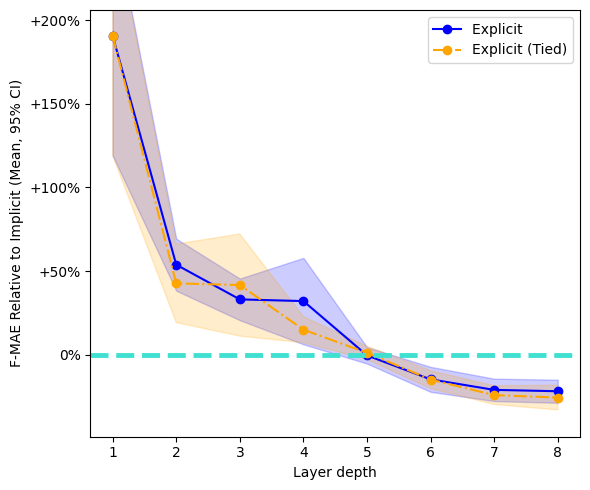

In [ ]:
rep = 'PaiNN'
# rep = 'SO3net'
# rep = 'SchNet'
dataset = 'MD17'
# dataset = 'MD22'

qs = [
    f'type=="{PRIMARY_DEQ}"',
    'n_z<200',
    f'AtomisticRepresentationClass=="{rep}"',
    f'Dataset=="{dataset}"'
]
dmax = 8
summarize=True
plot_individual=False
    
# summarize=False
# plot_individual=True

postfix = None
mean = False

normalize="relative"
ylim=(-.4, 1.8)
band=None
mean=True
postfix = '-relative-mean'

band='conf'
postfix = '-relative-mean-conf'
ylim=(-.49, 2.06)

fig, axes = plot_depth_grid(
    bests.query(' and '.join(qs)),
    baseline_col=PRIMARY_DEQ_COL,
    deq_col=PRIMARY_DEQ_COL,
    
    split=None,
    # split="n_z",
    # hue=None,
    
    row="n_z",
    col="AtomisticRepresentationClass",
    # col_order=['PaiNN', 'SO3net', 'SchNet'],

    figsize_per_ax=(6, 5),
    
    series=(
        dict(name="Explicit          ", prefix="fmae_best__explicit_",      linestyle="-" , color='blue'),
        dict(name="Explicit (Tied)",    prefix="fmae_best__explicit-tied_", linestyle="-.", color='orange'),
        # dict(name="Explicit (TT)",      prefix="fmae_best__explicit-tt_", linestyle=":", color='red'),
    ),
    legend='in ax',
    
    
    depth_range=range(1, dmax+1),
    summarize=summarize,

    plot_individual=plot_individual,
    
    normalize=normalize,
    band=band,
    ylim=ylim,
    mean=mean,

)

if postfix is not None:
    pat = proj_path(f'../imlff-paper/figures/FMAE-relative-to-{PRIMARY_DEQ}--{rep.lower()}-128-{dataset.lower()}{postfix}.pdf')
    fig.savefig(pat, bbox_inches='tight')
    print(pat)


In [30]:
sel = comparison
for q in [
    # 'molecule == "AT-AT-CG-CG"',
    # f'Dataset == "{dataset}"',
    # 'Dataset == "MD22"',
    # f'AtomisticRepresentationClass == "{rep}"',
    'n_z==128',
]:
    sel = sel.query(q)
s = metrics_and_style(
    sel,
    # a_inc=layer_and_tied, r_inc=None,
    a_inc=None, r_inc=layer_and_tied,
    
    parity=None, 
    # tied_by_row='sort',
    tied_by_row=False,
    gcols = [
        # 'Tied',
        
        'AtomisticRepresentationClass',
        'Dataset', 
        'n_z', 
        'n_atoms', 'molecule',
    ],
    primary_deq_col=PRIMARY_DEQ_COL,
    secondary_deq_col=SECONDARY_DEQ_COL,
)   
s

median/mean [ 0.66434118  0.04387064 -0.02566396 -0.01899153 -0.0294819   0.2239507 ]
median/mean [0.66434118 0.1514096  0.02964879 0.04165003 1.3212994 ]
median/mean [ 0.53837223  0.02413704 -0.02903448]
median/mean [0.53837223]
median/mean [ 1.46768457  0.1428026  -0.13400167]
median/mean [1.46768457]


(<Figure size 1200x300 with 3 Axes>,
 array([[<Axes: xlabel='Layer depth', ylabel='F-MAE Δ to Implicit (Median, !5, !95)'>,
         <Axes: xlabel='Layer depth'>, <Axes: xlabel='Layer depth'>]],
       dtype=object))

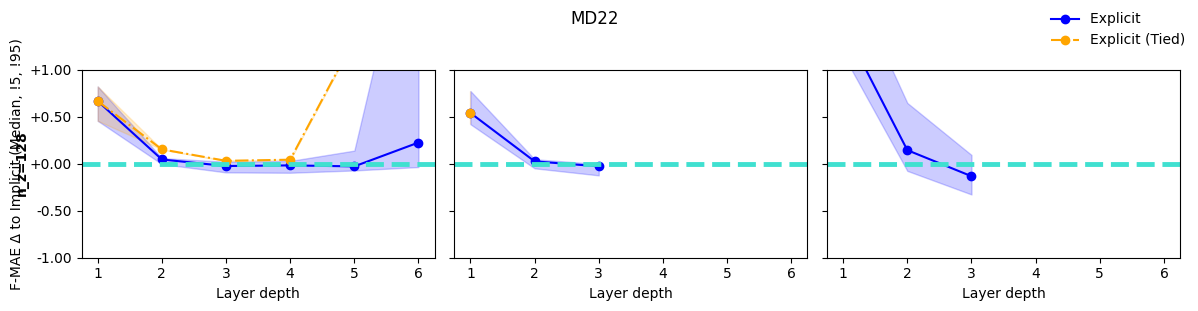

In [31]:
qs = [
    f'type=="{PRIMARY_DEQ}"',
    # 'n_z<200',
    # 'AtomisticRepresentationClass=="PaiNN"',
    # 'Dataset=="MD17"'
    'Dataset=="MD22"'
]

# fig, axes = \
plot_depth_grid(
    bests.query(' and '.join(qs)),
    baseline_col=PRIMARY_DEQ_COL,
    deq_col=PRIMARY_DEQ_COL,
    series=(
        dict(name="Explicit          ", prefix="fmae_best__explicit_",      linestyle="-" , color='blue'),
        dict(name="Explicit (Tied)",    prefix="fmae_best__explicit-tied_", linestyle="-.", color='orange'),
    ),
)

# Styled Accuracy Table

In [33]:
groupby = [
    'AtomisticRepresentationClass', 
    # 'Dataset',
]

if groupby:
    groups = [x for x in comparison.groupby(groupby)]

    group_key, group = groups[0]
    model = group_key[0]
    group = group.drop(columns=['Dataset'])

    print(group_key)
else: 
    group = comparison
    group_key=[]
    model = None

by_molecule=True
s = metrics_and_style(
    group,
    a_inc=None, 
    parity=None, 
    r_inc=layer_and_tied,
    tied_by_row=True,
    
    explicit_header=f'Explicit {model}<br><span style="font-style:italic">(by layer count)</span>',
    implicit_header=f'I-{model}<br><span style="font-style:italic">(by norm)</span>',
    
    primary_title='<span style="font-style:italic">LN</span>',
    secondary_title='<span style="font-style:italic">RMS</span>',
    
    # primary_title='Icon<sub>LN</sub>',
    # secondary_title='Icon<sub>RMS</sub>',

    by_molecule=by_molecule,
    invert=True,
    
    tied_inline=True,
    primary_color='#cfe8ff',
    primary_deq_col=PRIMARY_DEQ_COL,
    secondary_deq_col=SECONDARY_DEQ_COL,
    
    max_explicit_depth={'SchNet':3, 'SO3net':3}.get(model),
) 
s

('PaiNN',)


In [ ]:
views = []
keys = []
for key, group in comparison.groupby(['AtomisticRepresentationClass']):
    model = key[0]
    weight_tied_str = (model=='PaiNN')*', weight-tied models in grey'
    view = metrics_and_style(
        group.drop(columns=['Dataset']),
        a_inc=None, parity=None, r_inc=layer_and_tied,
        tied_by_row=True, by_molecule=True, invert=True, tied_inline=True,
        primary_color='#cfe8ff',
        explicit_header=f'Explicit {model}<br><span style="font-style:italic">(by layer count{weight_tied_str})</span>',
        implicit_header=f'I-{model}<br><span style="font-style:italic">(by norm)</span>',
        primary_title='<span style="font-style:italic">LN</span>',
        secondary_title='<span style="font-style:italic">UL</span>',
        primary_deq_col=PRIMARY_DEQ_COL, secondary_deq_col=SECONDARY_DEQ_COL,
        max_explicit_depth={'SchNet':3, 'SO3net':3}.get(model),
    )
    views.append(view)
    keys.append(key)

In [35]:
by_molecule = True
s = render_side_by_side(views[1], views[2])   # last expression in the cell -> renders
group_key = list(keys[1]) + list(keys[2])
print(group_key)
s

['SO3net', 'SchNet']


In [246]:
by_molecule = True
s = views[0]
group_key = keys[0]
print(group_key)
s

('PaiNN',)


In [249]:
by_molecule=False
group_key = []
s = metrics_and_style(
    comparison,
    a_inc=None, 
    parity=None, 
    r_inc=layer_and_tied,
    
    by_molecule=by_molecule,
    require_full=False,
    
    implicit_header=f'Implicit<br><span style="font-style:italic">(by norm)</span>',
    explicit_header=f'Explicit models<br><span style="font-style:italic">(by layer count, weight-tied models in grey)</span>',
    
    primary_title='<span style="font-style:italic">LN</span>',
    secondary_title='<span style="font-style:italic">UL</span>',
    
    # primary_title='Icon<sub>LN</sub>',
    # secondary_title='Icon<sub>UL</sub>',
    
    aggregation='mean',
    invert=True,
    
    tied_by_row=True,
    tied_inline=True,
    primary_color='#cfe8ff',
    primary_deq_col=PRIMARY_DEQ_COL,
    secondary_deq_col=SECONDARY_DEQ_COL,
    
    aggregate_then_delta=True,
)
s

# To PDF

In [250]:
import nest_asyncio  

in_paper_dir = True

nest_asyncio.apply()

pat = proj_path(f'{"../imlff-paper/tables/" * in_paper_dir}styled_accuracy_table{('_'.join(["_by_molecule"] + list(group_key))) * by_molecule}.pdf')
pat = styler_html_to_pdf(s, pat, landscape=True, scale=0.9, index_cols=2+(-1 * by_molecule))
print(pat)

~/imlff/../imlff-paper/tables/styled_accuracy_table.pdf


# Memory-Compute Plot

In [ ]:
def find_fastest_explicit_thats_better(row):
    imp = row['fmae_best__deq-merged_10']
    for layers in range(1,9):
        exp = row[f'fmae_best__explicit_{layers}']
        
        if np.isnan(exp):
            # assuming that next-largest explicit model WOULD beat implicit model
            # (in favor of explicit model bc of benefit of the doubt)
            print(f'nan found, returning {layers=}:', row.Dataset, row.molecule)
            return layers
        
        if exp<=imp:
            return layers
        
    print('all', exp, 'are worse')
    assert 0
    return layers
        
comparison['exp_beating_imp'] = comparison.apply(find_fastest_explicit_thats_better, axis=1)

nan found, returning layers=7: MD17 aspirin
nan found, returning layers=4: MD17 ethanol
nan found, returning layers=4: MD17 malonaldehyde
nan found, returning layers=7: MD17 salicylic_acid
nan found, returning layers=4: MD17 toluene
nan found, returning layers=4: MD17 uracil
nan found, returning layers=4: MD22 DHA
nan found, returning layers=4: MD17 aspirin
nan found, returning layers=4: MD17 benzene
nan found, returning layers=4: MD17 ethanol
nan found, returning layers=4: MD17 malonaldehyde
nan found, returning layers=4: MD17 paracetamol
nan found, returning layers=4: MD17 toluene
nan found, returning layers=4: MD22 double-walled_nanotube


In [ ]:
pat_iter_counts = proj_path('result_summary/mds/2026-06-25_iter-count.csv')
df_iter_counts = pd.read_csv(pat_iter_counts)
df_iter_counts = (
    df_iter_counts
    .sort_values('_step')
    .drop_duplicates('model_config__model_tag', keep='last')
)

df_iter_counts['constant'] = 'constant'
df_iter_counts['memory'] = 1

left_key = ['AtomisticRepresentationClass', 'molecule']
left = left_key + ['exp_beating_imp']
right_key = ['train__AtomisticRepresentationClass', 'train__molecule']

df_iter_counts = comparison[left].merge(
    df_iter_counts,
    left_on=left_key,
    right_on=right_key,
    how="inner",
    validate="1:1",
)
for k in right_key:
    del df_iter_counts[k]

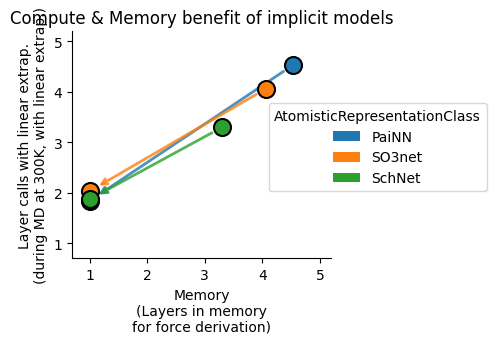

In [ ]:

scatter_df = df_iter_counts#.query('AtomisticRepresentationClass in ["SchNet]')

# ---- configuration ---------------------------------------------------------

HUE = 'AtomisticRepresentationClass'

# primary blob: memory vs iteration count
PRIMARY_X = 'memory'
PRIMARY_Y = 'avg_iterations'

# secondary blob: exp_beating_imp on both axes (overlaid on same ax)
SECONDARY_X = 'exp_beating_imp'
SECONDARY_Y = 'exp_beating_imp'

# shared blob styling
SMOOTH_GRID_BINS = 200      # grid resolution for evaluation (not a histogram)
FILL_BANDS = 8             # number of filled contour bands
LEVEL_MIN = 0.15           # lowest contour as fraction of per-group peak
PRIMARY_ALPHA = 0.3
SECONDARY_ALPHA = 0.3

SHOW_PRIMARY_MEANS = True
SHOW_SECONDARY_MEANS = True
SHOW_MEAN_ARROWS = True     # arrow from exp_ (secondary) mean -> primary mean
MEAN_SIZE = 150
ARROW_ALPHA = 0.8
# ----------------------------------------------------------------------------

from matplotlib.patches import Patch

ax_by = 'constant'
# ax_by = 'AtomisticRepresentationClass'

# hue -> color mapping
hue_levels = scatter_df[HUE].unique()
palette = sns.color_palette(n_colors=len(hue_levels))
color_map = dict(zip(hue_levels, palette))

# faceted layout (no base density; we draw the blobs ourselves)
g = sns.FacetGrid(scatter_df, col=ax_by, col_wrap=3, sharex=True, sharey=True)
g.set_titles('{col_name}')
g.set_axis_labels(f'{PRIMARY_X} / {SECONDARY_X}', f'{PRIMARY_Y} / {SECONDARY_Y}')


def _facet_group(facet_val):
    """Yield (cls, sub_df) for each hue group present in a facet."""
    facet_df = scatter_df[scatter_df[ax_by] == facet_val]
    for cls, grp in facet_df.groupby(HUE, observed=True):
        if cls in color_map:
            yield cls, grp

def _mean_xy(sub, xcol, ycol):
    x, y = sub[xcol].mean(), sub[ycol].mean()
        
    if np.isnan(x) or np.isnan(y):
        return None
    return x, y


def _plot_mean(ax, xy, color):
    ax.scatter(
        xy[0], xy[1],
        color=color, edgecolor='black',
        linewidth=1.5, s=MEAN_SIZE, zorder=5,
    )


for facet_val, ax in g.axes_dict.items():
    for cls, grp in _facet_group(facet_val):
        color = color_map[cls]

        primary_mean = _mean_xy(grp, PRIMARY_X, PRIMARY_Y)
        secondary_mean = _mean_xy(grp, SECONDARY_X, SECONDARY_Y)

        # arrow: exp_ (secondary) mean -> primary mean
        if SHOW_MEAN_ARROWS and primary_mean and secondary_mean:
            ax.annotate(
                '', xy=primary_mean, xytext=secondary_mean,
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2, alpha=ARROW_ALPHA, shrinkA=8, shrinkB=8),
                zorder=4,
            )

        # mean markers (drawn on top of the arrows)
        if SHOW_PRIMARY_MEANS and primary_mean:
            _plot_mean(ax, primary_mean, color)
        if SHOW_SECONDARY_MEANS and secondary_mean:
            _plot_mean(ax, secondary_mean, color)

# hue legend (proxy patches, since we draw blobs manually)
handles = [Patch(facecolor=color_map[c], label=str(c)) for c in color_map]
g.figure.legend(handles=handles, title=HUE, loc='center right',
                # bbox_to_anchor=(1.12, 0.5)
                bbox_to_anchor=(.52, 0.5)
                )

ax, = g.figure.axes
ax.set_title('Compute & Memory benefit of implicit models')
ax.set_ylabel('Layer calls with linear extrap.\n(during MD at 300K, with linear extrap.)')
ax.set_xlabel('Memory\n(Layers in memory\nfor force derivation)')
ax.set_xticks([1,2,3,4,5])
ax.set_yticks([1,2,3,4,5])
ax.set_xlim([.7, 5.2])
ax.set_ylim([.7, 5.2])

plt.gcf().savefig('speed-memory.pdf')